# Flight Delay Analysis and Prediction
**Aviation ML mini-project | Classification | 1–2 day build**

## Objective
Analyze historical U.S. flight records and classify whether a flight arrives **15 minutes or more late**.

**Dataset:** U.S. Bureau of Transportation Statistics (BTS), On-Time Performance data: https://www.transtats.bts.gov/ONTIME/

Download one month of On-Time Performance data as CSV and save it to `data/flight_data.csv`. The BTS portal interface may change, so select the On-Time Performance table and a month available for download.

**Algorithms:** Logistic Regression, KNN, SVM, and K-Means. K-Means is unsupervised clustering and is evaluated separately, not as a classifier.


## 1. Install dependencies

In [4]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Load data

In [5]:
from pathlib import Path

DATA_PATH = Path("../data/flight_data.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/flight_data.csv")

print("File exists:", DATA_PATH.exists())
print("File path:", DATA_PATH.resolve())

with open(DATA_PATH, "r", encoding="utf-8-sig") as f:
    for i in range(5):
        print(repr(f.readline()))

File exists: True
File path: E:\ML Project\flight_delay_analysis_prediction_project\flight_delay_prediction_project\data\flight_data.csv
'FL_DATE,OP_UNIQUE_CARRIER,FLIGHT_NUMBER,ORIGIN,DEST,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,DELAYED_15,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,TAXI_IN,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY\n'
'2025-01-01,DL,333,LAS,JFK,15:17,14:41,-36.0,0,302.0,270.0,6.0,0.0,0.0,0.0,0.0,0.0\n'
'2025-01-01,DL,336,DEN,JFK,12:04,12:37,33.0,1,219.0,244.0,5.0,0.0,8.0,25.0,0.0,0.0\n'
'2025-01-01,DL,343,SLC,JFK,14:19,13:36,-43.0,0,285.0,243.0,7.0,0.0,0.0,0.0,0.0,0.0\n'
'2025-01-01,DL,363,SFO,JFK,20:36,20:05,-31.0,0,336.0,310.0,18.0,0.0,0.0,0.0,0.0,0.0\n'


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, roc_auc_score, ConfusionMatrixDisplay,
    silhouette_score
)

RANDOM_STATE = 42
DATA_PATH = Path("../data/flight_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/flight_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Download a BTS On-Time Performance CSV and save it as data/flight_data.csv. See README.md.")

df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = [c.strip().upper() for c in df.columns]
print("Dataset shape:", df.shape)
print(df.columns.tolist())
df.head()


Dataset shape: (2386, 17)
['FL_DATE', 'OP_UNIQUE_CARRIER', 'FLIGHT_NUMBER', 'ORIGIN', 'DEST', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'DELAYED_15', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'TAXI_IN', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']


,FL_DATE,OP_UNIQUE_CARRIER,FLIGHT_NUMBER,ORIGIN,DEST,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,DELAYED_15,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,TAXI_IN,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,2025-01-01,DL,333,LAS,JFK,15:17,14:41,-36.0,0,302.0,270.0,6.0,0.0,0.0,0.0,0.0,0.0
1,2025-01-01,DL,336,DEN,JFK,12:04,12:37,33.0,1,219.0,244.0,5.0,0.0,8.0,25.0,0.0,0.0
2,2025-01-01,DL,343,SLC,JFK,14:19,13:36,-43.0,0,285.0,243.0,7.0,0.0,0.0,0.0,0.0,0.0
3,2025-01-01,DL,363,SFO,JFK,20:36,20:05,-31.0,0,336.0,310.0,18.0,0.0,0.0,0.0,0.0,0.0
4,2025-01-01,DL,367,SAN,JFK,15:29,18:42,193.0,1,329.0,312.0,21.0,0.0,0.0,0.0,0.0,193.0


## 3. Select features and define target
Target: `1` when `ARR_DELAY >= 15` minutes, otherwise `0`.

To avoid target leakage, actual arrival delay and actual departure delay are not predictors. We use scheduled information and flight identifiers commonly available before departure.


In [7]:
candidate_features = [
    "MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME", "CRS_ARR_TIME",
    "DISTANCE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST"
]
if "ARR_DELAY" not in df.columns:
    raise ValueError("ARR_DELAY column not found. Please use BTS On-Time Performance data.")

features = [c for c in candidate_features if c in df.columns]
if not features:
    raise ValueError("No expected feature columns found. Check that this is BTS On-Time Performance data.")

data = df[features + ["ARR_DELAY"]].copy()
data["ARR_DELAY"] = pd.to_numeric(data["ARR_DELAY"], errors="coerce")
data = data.dropna(subset=["ARR_DELAY"])
data["DELAYED_15"] = (data["ARR_DELAY"] >= 15).astype(int)
data = data.drop(columns=["ARR_DELAY"])

numeric_candidates = ["MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME", "CRS_ARR_TIME", "DISTANCE"]
for col in numeric_candidates:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.reset_index(drop=True)
X = data[features].copy()
y = data["DELAYED_15"].astype(int)
print("Rows used:", len(data))
print("Feature columns:", features)
print("15+ minute delay rate:", round(y.mean(), 3))
data.head()


Rows used: 2386
Feature columns: ['CRS_ARR_TIME', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST']
15+ minute delay rate: 0.181


,CRS_ARR_TIME,OP_UNIQUE_CARRIER,ORIGIN,DEST,DELAYED_15
0,NaN,DL,LAS,JFK,0
1,NaN,DL,DEN,JFK,1
2,NaN,DL,SLC,JFK,0
3,NaN,DL,SFO,JFK,0
4,NaN,DL,SAN,JFK,1


## 4. Exploratory analysis

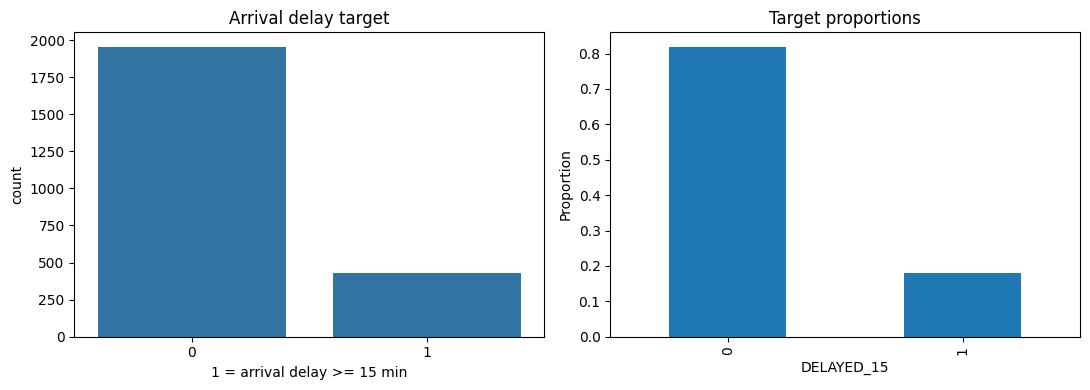

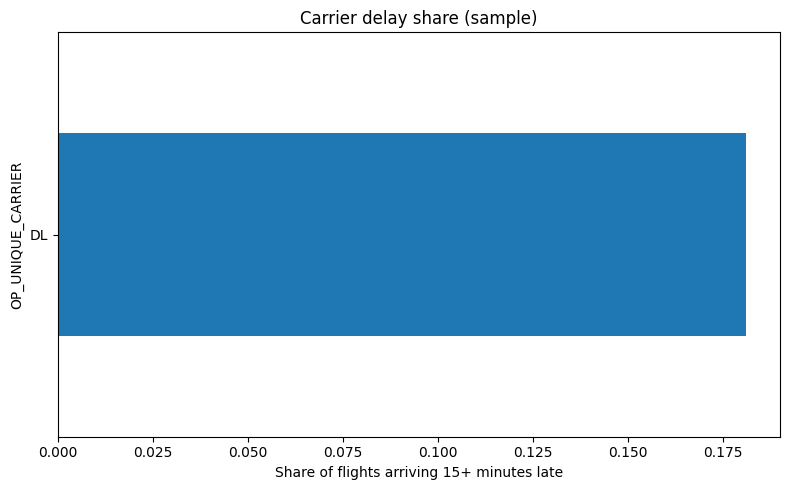

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=data, x="DELAYED_15", ax=axes[0])
axes[0].set_title("Arrival delay target")
axes[0].set_xlabel("1 = arrival delay >= 15 min")
y.value_counts(normalize=True).sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Target proportions")
axes[1].set_ylabel("Proportion")
plt.tight_layout()
plt.show()

if "OP_UNIQUE_CARRIER" in df.columns and "ARR_DELAY" in df.columns:
    carrier_data = df[["OP_UNIQUE_CARRIER", "ARR_DELAY"]].copy()
    carrier_data["ARR_DELAY"] = pd.to_numeric(carrier_data["ARR_DELAY"], errors="coerce")
    carrier_data = carrier_data.dropna()
    carrier_rates = carrier_data.assign(delayed=carrier_data["ARR_DELAY"] >= 15).groupby("OP_UNIQUE_CARRIER")["delayed"].mean()
    carrier_rates.sort_values().tail(12).plot(kind="barh", figsize=(8, 5), title="Carrier delay share (sample)")
    plt.xlabel("Share of flights arriving 15+ minutes late")
    plt.tight_layout()
    plt.show()


## 5. Train/test split and preprocessing

In [9]:
if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError("Need at least two examples of each target class. Download a larger monthly sample.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = [c for c in features if c in numeric_candidates]
categorical_features = [c for c in features if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Train rows:", len(X_train), "| Test rows:", len(X_test))


Train rows: 1908 | Test rows: 478


In [17]:

# Fix the dataset preparation for the available CSV columns

# Convert scheduled arrival time (HH:MM) to minutes after midnight
time_parts = df["CRS_ARR_TIME"].astype(str).str.extract(
    r"^\s*(\d{1,2}):(\d{2})"
)
df["CRS_ARR_TIME"] = (
    pd.to_numeric(time_parts[0], errors="coerce") * 60
    + pd.to_numeric(time_parts[1], errors="coerce")
)

# Define the target
df["DELAYED_15"] = pd.to_numeric(df["DELAYED_15"], errors="coerce")
df = df.dropna(subset=["DELAYED_15"]).copy()
df["DELAYED_15"] = df["DELAYED_15"].astype(int)

# Use only columns that exist and are available before the flight
numeric_features = ["CRS_ARR_TIME", "CRS_ELAPSED_TIME"]
categorical_features = ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]
feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df["DELAYED_15"].copy()

# Ensure numeric features really are numeric
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Prepare preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split data for training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Features:", feature_columns)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Usable numeric features:", X[numeric_features].notna().sum().to_dict())


Features: ['CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST']
Training rows: 1908
Testing rows: 478
Usable numeric features: {'CRS_ARR_TIME': 0, 'CRS_ELAPSED_TIME': 2386}


## 6. Train three supervised classifiers

In [18]:
estimators = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE)
}

fitted = {}
metric_rows = []

for name, estimator in estimators.items():
    model = Pipeline([("preprocess", preprocessor), ("classifier", estimator)])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob)
    })
    fitted[name] = model
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))

results = pd.DataFrame(metric_rows).sort_values("F1", ascending=False).reset_index(drop=True)
results


C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



 Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.63      0.72       391
           1       0.24      0.52      0.32        87

    accuracy                           0.61       478
   macro avg       0.55      0.57      0.52       478
weighted avg       0.74      0.61      0.65       478


 KNN
              precision    recall  f1-score   support

           0       0.82      0.97      0.89       391
           1       0.14      0.02      0.04        87

    accuracy                           0.80       478
   macro avg       0.48      0.50      0.46       478
weighted avg       0.69      0.80      0.73       478



C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_A


 SVM (RBF)
              precision    recall  f1-score   support

           0       0.85      0.63      0.72       391
           1       0.24      0.52      0.32        87

    accuracy                           0.61       478
   macro avg       0.55      0.57      0.52       478
weighted avg       0.74      0.61      0.65       478



C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.608787,0.236842,0.517241,0.324910,0.613179
1,SVM (RBF),0.608787,0.236842,0.517241,0.324910,0.589103
2,KNN,0.797071,0.142857,0.022989,0.039604,0.550651


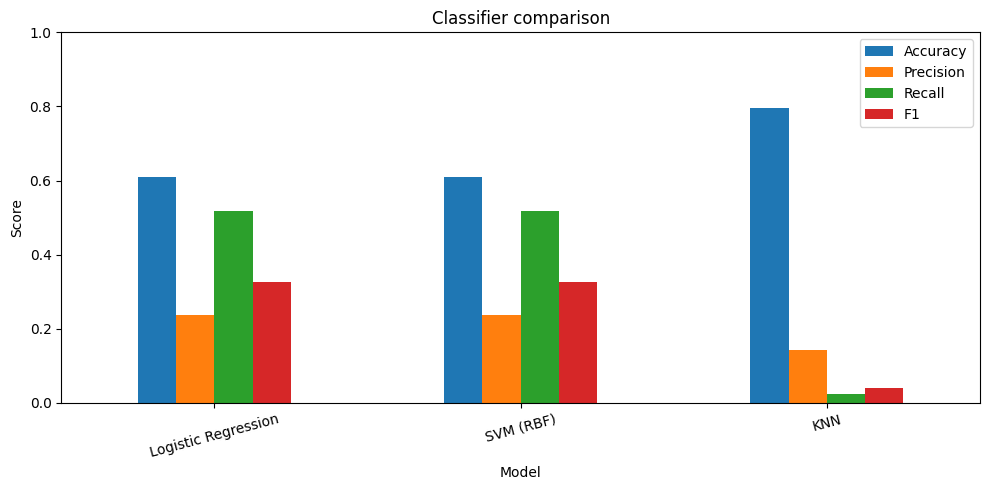

C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Best model by F1: Logistic Regression


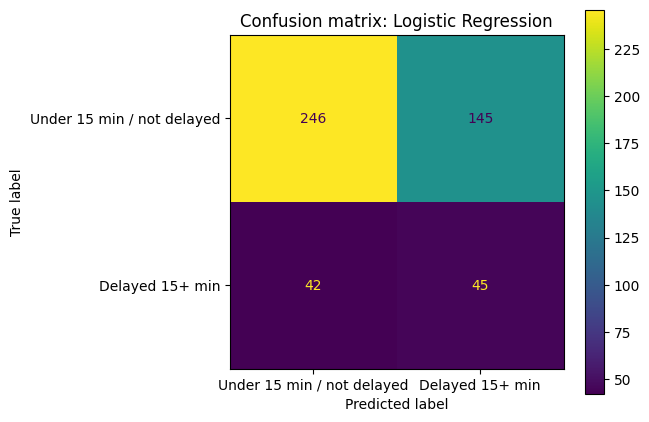

In [19]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=15
)
plt.title("Classifier comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

best_name = results.loc[0, "Model"]
best_model = fitted[best_name]
best_predictions = best_model.predict(X_test)
print("Best model by F1:", best_name)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Under 15 min / not delayed", "Delayed 15+ min"]
)
plt.title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.show()


## 7. K-Means clustering (unsupervised)

In [20]:
# Fit preprocessing on the training split for the clustering demonstration.
cluster_size = min(4000, len(X_train))
cluster_sample = X_train.sample(n=cluster_size, random_state=RANDOM_STATE)
cluster_matrix = preprocessor.fit_transform(cluster_sample)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
cluster_ids = kmeans.fit_predict(cluster_matrix)

score_size = min(1500, cluster_size)
rng = np.random.RandomState(RANDOM_STATE)
score_idx = rng.choice(cluster_size, size=score_size, replace=False)
silhouette = silhouette_score(cluster_matrix[score_idx], cluster_ids[score_idx]) if len(set(cluster_ids[score_idx])) > 1 else float("nan")

cluster_report = pd.DataFrame({
    "Cluster": cluster_ids,
    "Delayed_15": y_train.loc[cluster_sample.index].to_numpy()
})
print("Silhouette score (sample):", round(float(silhouette), 4))
display(cluster_report.groupby("Cluster").agg(
    Flights=("Delayed_15", "size"),
    Delay_Rate=("Delayed_15", "mean")
).sort_values("Delay_Rate", ascending=False))


C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Silhouette score (sample): 0.3834


,Flights,Delay_Rate
Cluster,,
1,1016,0.203740
0,872,0.155963
2,20,0.100000


## 8. Predict one example

In [21]:
example = X_test.iloc[[0]]
display(example)
print("Predicted delayed (1 means 15+ minutes):", int(best_model.predict(example)[0]))
print("Estimated probability of 15+ minute delay:",
      round(float(best_model.predict_proba(example)[0, 1]), 3))


,CRS_ARR_TIME,CRS_ELAPSED_TIME,OP_UNIQUE_CARRIER,ORIGIN,DEST
840,NaN,251.0,DL,SJU,JFK


Predicted delayed (1 means 15+ minutes): 0
Estimated probability of 15+ minute delay: 0.483


C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\hanum\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['CRS_ARR_TIME']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## 9. Save results

In [22]:
from pathlib import Path
results_dir = Path("../results")
if not results_dir.exists():
    results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(results_dir / "model_comparison.csv", index=False)
print("Saved results to", results_dir / "model_comparison.csv")


Saved results to ..\results\model_comparison.csv


## 10. Conclusions (complete after running)
- Best classifier by F1: **[copy from results]**
- Delayed-flight recall: **[copy measured value]**
- Main EDA observation: **[describe your chart]**
- K-Means cluster with the highest delay share: **[copy from cluster table]**
- Limitations: a single month may not represent other seasons; weather and live air-traffic conditions are not included; performance is educational and not suitable for operational flight decisions.
